# Chapter 7: How to Picture Neural Networks: In Your Head and on Paper

**Book:** *Grokking Deep Learning*  
**Author:** Andrew W. Trask

## Neural Network Visualization and Forward Propagation Using NumPy

### Tujuan Pembelajaran

Pada bab ini, kita mempelajari cara memahami struktur *neural network* melalui visualisasi dan perhitungan matematis. Kita akan melihat hubungan antara neuron, bobot (*weights*), bias, dan proses *forward propagation*.

Setiap neuron menerima masukan, mengalikannya dengan bobot, menambahkan bias, kemudian menerapkan fungsi aktivasi untuk menghasilkan keluaran. Proses tersebut menjadi dasar bagaimana jaringan saraf tiruan memproses data.

Implementasi dilakukan menggunakan Python dan NumPy agar perhitungan jaringan saraf dapat dipahami secara bertahap.

### 1. Import Library

NumPy digunakan untuk melakukan operasi matematika dan perkalian matriks, sedangkan Matplotlib digunakan untuk menggambarkan struktur jaringan saraf tiruan.

Visualisasi membantu kita memahami bahwa sebuah *neural network* terdiri dari beberapa lapisan (*layers*) yang saling terhubung melalui bobot.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

### 2. Visualisasi Struktur Neural Network

Jaringan saraf yang digunakan pada contoh ini memiliki tiga neuron input, empat neuron pada *hidden layer*, dan dua neuron output.

- **Input layer:** menerima data masukan.
- **Hidden layer:** memproses informasi menggunakan bobot, bias, dan fungsi aktivasi.
- **Output layer:** menghasilkan nilai keluaran dari jaringan.

Setiap neuron pada satu lapisan terhubung dengan neuron di lapisan berikutnya. Garis penghubung menggambarkan koneksi yang memiliki bobot masing-masing.

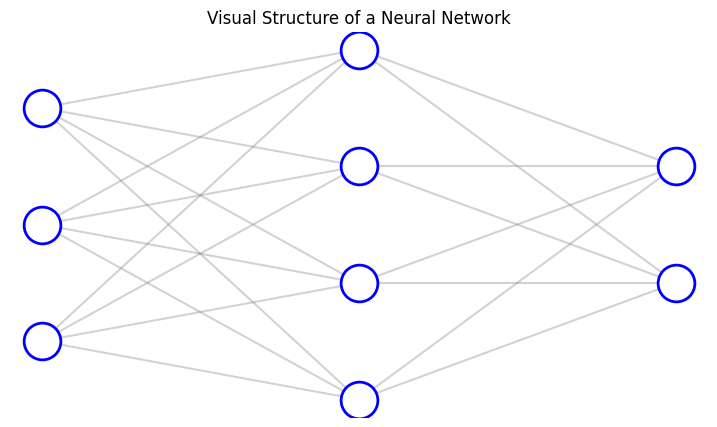

In [6]:
def draw_network(layer_sizes):
    fig, ax = plt.subplots(figsize=(9, 5))

    positions = []
    max_neurons = max(layer_sizes)

    for layer_idx, n_neurons in enumerate(layer_sizes):
        x = layer_idx
        y_positions = np.linspace(
            (max_neurons - n_neurons) / 2,
            (max_neurons + n_neurons) / 2 - 1,
            n_neurons
        )
        positions.append([(x, y) for y in y_positions])

    # Menggambar koneksi antarlapisan
    for layer_idx in range(len(positions) - 1):
        for x1, y1 in positions[layer_idx]:
            for x2, y2 in positions[layer_idx + 1]:
                ax.plot(
                    [x1, x2], [y1, y2],
                    color="gray", alpha=0.35
                )

    # Menggambar neuron
    for layer in positions:
        for x, y in layer:
            ax.scatter(
                x, y, s=700,
                facecolors="white",
                edgecolors="blue",
                linewidths=2,
                zorder=3
            )

    ax.set_xticks(range(len(layer_sizes)))
    ax.set_xticklabels(
        ["Input Layer", "Hidden Layer", "Output Layer"]
    )
    ax.set_title("Visual Structure of a Neural Network")
    ax.axis("off")
    plt.show()


draw_network([3, 4, 2])

### 3. Memahami Weights dan Bias

*Weights* menentukan seberapa besar pengaruh suatu input terhadap neuron tujuan. Sementara itu, *bias* merupakan nilai tambahan yang memungkinkan neuron menggeser hasil perhitungannya.

Dalam jaringan dengan tiga neuron input dan empat neuron pada *hidden layer*, matriks bobot memiliki ukuran \(3 \times 4\). Setiap baris mewakili neuron input dan setiap kolom mewakili neuron pada *hidden layer*.

Bias untuk *hidden layer* memiliki empat nilai karena terdapat empat neuron. Pada tahap ini, bobot dan bias diinisialisasi menggunakan nilai acak untuk keperluan demonstrasi, bukan hasil pelatihan model.

In [7]:
# Jumlah neuron pada setiap lapisan
input_size = 3
hidden_size = 4
output_size = 2

# Bobot dan bias dari input ke hidden layer
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))

# Bobot dan bias dari hidden layer ke output layer
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

print("Dimensi W1:", W1.shape)
print("Dimensi b1:", b1.shape)
print("Dimensi W2:", W2.shape)
print("Dimensi b2:", b2.shape)

Dimensi W1: (3, 4)
Dimensi b1: (1, 4)
Dimensi W2: (4, 2)
Dimensi b2: (1, 2)



### 4. Fungsi Aktivasi Sigmoid

Fungsi aktivasi digunakan untuk mengubah hasil perhitungan pada neuron agar menghasilkan keluaran sesuai dengan karakteristik fungsi yang digunakan. Pada contoh ini, fungsi aktivasi yang digunakan adalah *sigmoid*, dengan persamaan sebagai berikut:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

Fungsi sigmoid memetakan nilai input ke dalam rentang 0 hingga 1. Fungsi ini mengubah hasil perhitungan antara bobot dan input menjadi keluaran neuron yang dapat diteruskan ke lapisan berikutnya.

Penggunaan fungsi sigmoid pada contoh ini bertujuan untuk mendemonstrasikan konsep fungsi aktivasi dalam jaringan saraf tiruan. Pada arsitektur jaringan yang lebih modern, fungsi aktivasi lain, seperti ReLU (*Rectified Linear Unit*), juga sering digunakan sesuai dengan kebutuhan dan karakteristik permasalahan.


Input: [-3 -1  0  1  3]
Output sigmoid: [0.04742587 0.26894142 0.5        0.73105858 0.95257413]


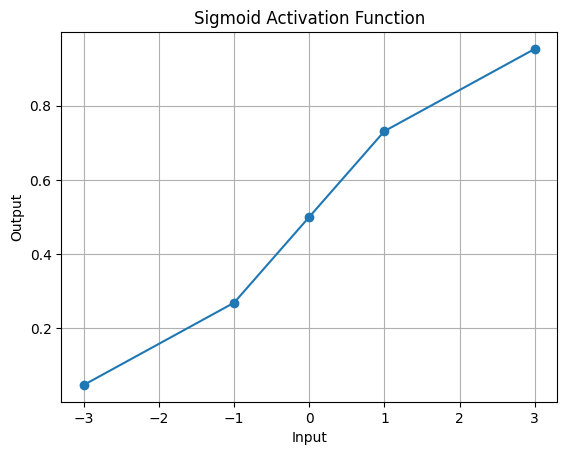

In [8]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


values = np.array([-3, -1, 0, 1, 3])
outputs = sigmoid(values)

print("Input:", values)
print("Output sigmoid:", outputs)

plt.plot(values, outputs, marker="o")
plt.title("Sigmoid Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()


### 5. Forward Propagation

*Forward propagation* adalah proses mengalirkan data dari lapisan input (*input layer*) hingga menghasilkan keluaran (*output layer*). Proses ini dilakukan secara berurutan, mulai dari perhitungan pada *hidden layer* hingga menghasilkan prediksi jaringan.

Pertama, data input dikalikan dengan bobot \(W_1\), kemudian ditambahkan dengan bias \(b_1\). Hasil perhitungan tersebut selanjutnya diproses menggunakan fungsi aktivasi sigmoid untuk menghasilkan keluaran *hidden layer*.

$$
H = \sigma(XW_1 + b_1)
$$

Selanjutnya, keluaran *hidden layer* \(H\) dikalikan dengan bobot \(W_2\), kemudian ditambahkan dengan bias \(b_2\). Hasilnya kembali diproses menggunakan fungsi aktivasi sigmoid untuk menghasilkan prediksi jaringan.

$$
\hat{Y} = \sigma(HW_2 + b_2)
$$

Simbol \(\hat{Y}\) menunjukkan nilai prediksi yang dihasilkan oleh jaringan saraf tiruan. Pada tahap awal, bobot dan bias umumnya diinisialisasi dengan nilai awal sebelum proses pelatihan dilakukan. Oleh karena itu, prediksi yang dihasilkan pada tahap ini belum tentu akurat karena parameter jaringan belum dioptimalkan melalui proses pelatihan.


In [9]:
# Contoh satu data dengan tiga fitur
X = np.array([[0.5, 0.2, 0.8]])

# Input menuju hidden layer
z1 = X @ W1 + b1
hidden_output = sigmoid(z1)

# Hidden layer menuju output layer
z2 = hidden_output @ W2 + b2
prediction = sigmoid(z2)

print("Input:", X)
print("Hidden layer output:", hidden_output)
print("Final prediction:", prediction)

Input: [[0.5 0.2 0.8]]
Hidden layer output: [[0.45659624 0.57885833 0.56683577 0.63237474]]
Final prediction: [[0.11544154 0.12852542]]



### 6. Memeriksa Dimensi Matriks

Perkalian matriks harus memenuhi aturan dimensi, yaitu jumlah kolom pada matriks pertama harus sama dengan jumlah baris pada matriks kedua. Sebagai contoh, jika matriks input \(X\) memiliki ukuran \(1 \times 3\) dan matriks bobot pertama \(W_1\) berukuran \(3 \times 4\), hasil perkaliannya akan menghasilkan matriks berukuran \(1 \times 4\).

$$
(1 \times 3)(3 \times 4) = (1 \times 4)
$$

Hasil tersebut sesuai dengan jumlah neuron pada *hidden layer*, yaitu 4 neuron. Selanjutnya, keluaran *hidden layer* yang berukuran \(1 \times 4\) dikalikan dengan matriks bobot kedua \(W_2\) yang berukuran \(4 \times 2\). Hasilnya adalah matriks berukuran \(1 \times 2\), sesuai dengan jumlah neuron pada *output layer*, yaitu 2 neuron.

$$
(1 \times 4)(4 \times 2) = (1 \times 2)
$$

Pemeriksaan dimensi matriks membantu memastikan bahwa setiap operasi perkalian matriks dalam jaringan saraf tiruan memiliki ukuran yang sesuai. Dengan demikian, kesalahan dimensi saat implementasi dapat dihindari.


In [10]:
print("Dimensi input:", X.shape)
print("Dimensi W1:", W1.shape)
print("Dimensi hidden output:", hidden_output.shape)
print("Dimensi W2:", W2.shape)
print("Dimensi prediction:", prediction.shape)

assert X.shape[1] == W1.shape[0]
assert hidden_output.shape[1] == W2.shape[0]

print("Semua dimensi matriks sesuai.")

Dimensi input: (1, 3)
Dimensi W1: (3, 4)
Dimensi hidden output: (1, 4)
Dimensi W2: (4, 2)
Dimensi prediction: (1, 2)
Semua dimensi matriks sesuai.


### 7. Kesimpulan

Pada bab ini, kita mempelajari cara merepresentasikan jaringan saraf tiruan melalui visualisasi dan operasi matriks. Jaringan terdiri dari lapisan input, *hidden layer*, dan output yang saling terhubung melalui bobot.

Kita juga mempelajari peran bias, fungsi aktivasi sigmoid, serta proses *forward propagation*. Proses ini menunjukkan bagaimana data input diproses menjadi keluaran melalui beberapa lapisan.

Implementasi ini masih menggunakan bobot acak, sehingga belum mencakup proses pembelajaran atau pembaruan bobot. Pemahaman struktur dan alur perhitungan menjadi dasar untuk mempelajari bagaimana jaringan saraf dilatih pada bab berikutnya.